   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 41.4 MB/s eta 0:00:00


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Libraries loaded successfully!

TASK 1: DATA ACQUISITION AND PREPROCESSING

Dataset loaded successfully!

Dataset shape:
(39405, 5)

Column names:
['Date', 'Source', 'Headlines', 'Teaser', 'Category']

First 5 rows:


,Date,Source,Headlines,Teaser,Category
0,"January, 1970",Medscape Special Reports,Special Report: Adult Vaccines -- New ACIP Rec...,New recommendations for already approved vacci...,Immunization
1,"January, 1970",Medscape Medical News,Combined Internet and Telephone Intervention M...,"In a randomized trial, combined Internet and t...",Substance Abuse and Addiction
2,"April, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Link Between Parental Alcoholism and Childhood...,It is proposed that depressed children identif...,Substance Abuse and Addiction
3,"November, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Methadone Dose in the Treatment of Opiate Depe...,The epidemic of heroin abuse within the US has...,Substance Abuse and Addiction
4,"March, 2000",Medscape Medical News,Magnet Treatment Had No Beneficial Effect on P...,A small study using one variety of magnet for ...,Pain Management



Missing values:
Date         0
Source       0
Headlines    0
Teaser       0
Category     0
dtype: int64

Number of documents after removing empty text:
39405

----------------------------------------------------------------------
CLEANED TEXT SAMPLES
----------------------------------------------------------------------

Sample 1
Original:
Special Report: Adult Vaccines -- New ACIP Recommendations New recommendations for already approved vaccines and a newly approved vaccine for meningococcal B infections -- what you need to know.

Cleaned:
special report adult vaccine acip recommendation recommendation already approved vaccine newly approved vaccine meningococcal infection need know
----------------------------------------------------------------------

Sample 2
Original:
Combined Internet and Telephone Intervention May Facilitate Smoking Cessation In a randomized trial, combined Internet and telephone treatment of smoking cessation outperformed static and dynamic Internet interventi

,Word,Frequency
0,patient,12724
1,risk,7112
2,study,6924
3,drug,6078
4,treatment,5596
5,pain,5557
6,cancer,5496
7,use,4946
8,disease,4034
9,therapy,3466


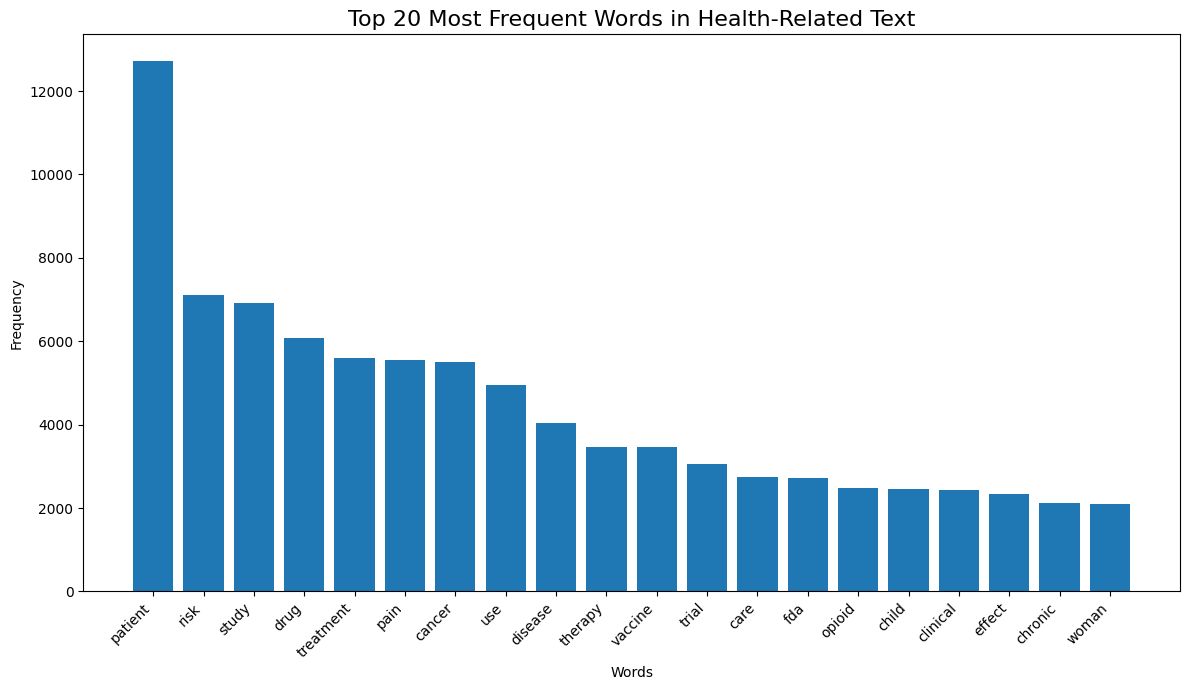

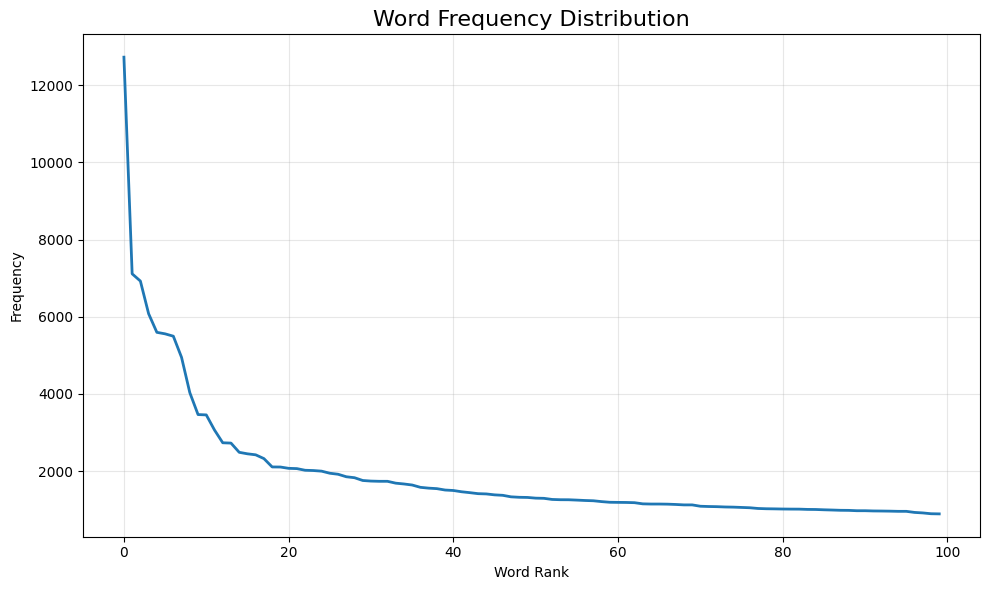

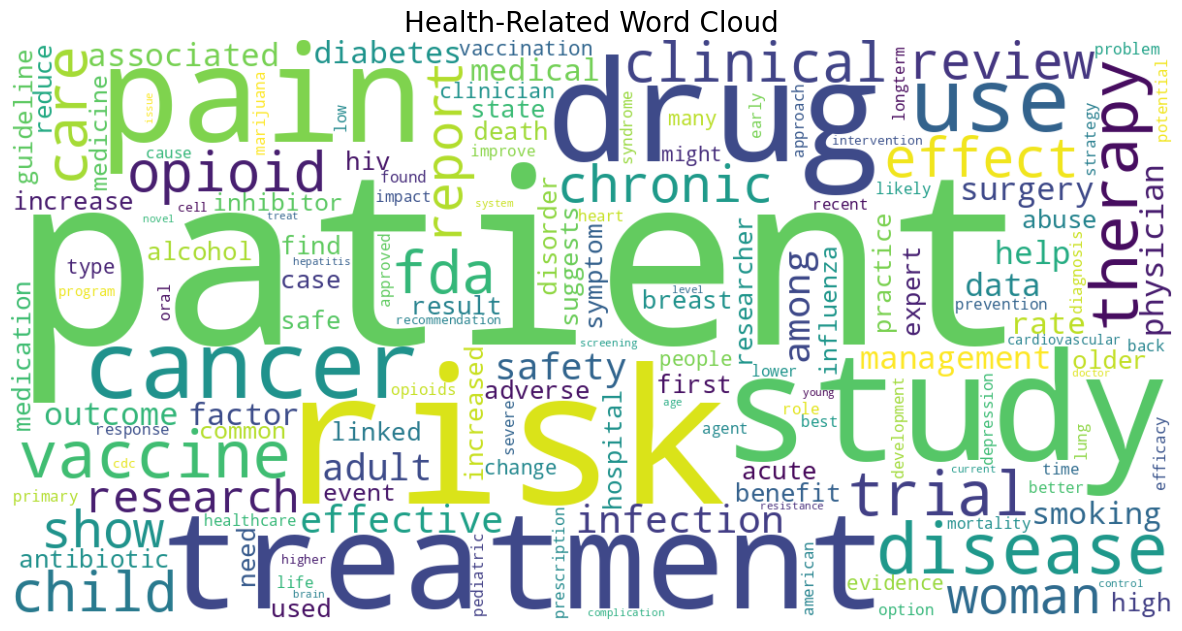


TASK 3: LDA TOPIC MODELING

Documents used for LDA:
39405

Initial vocabulary size:
29683

Vocabulary size after filtering:
9781

Corpus created successfully!
Number of documents: 39405
Number of vocabulary terms: 9781

Training LDA model...
Number of topics: 7

LDA model trained successfully!

TOP 5 WORDS FOR EACH TOPIC

Topic 1: drug, opioid, fda, use, safety

Topic 2: cancer, disease, clinical, review, trial

Topic 3: patient, pain, treatment, therapy, study

Topic 4: vaccine, vaccination, outbreak, cdc, influenza

Topic 5: risk, study, woman, among, adult

Topic 6: care, patient, report, physician, medical

Topic 7: use, infection, disorder, state, antibiotic

TOPIC WORD PROBABILITIES

Topic 1
drug                 0.0582
opioid               0.0344
fda                  0.0221
use                  0.0155
safety               0.0150

Topic 2
cancer               0.0559
disease              0.0374
clinical             0.0201
review               0.0161
trial                0.0145

To

,Topic,Documents
0,Topic 1,4896
1,Topic 2,5592
2,Topic 3,11293
3,Topic 4,1472
4,Topic 5,6197
5,Topic 6,7204
6,Topic 7,2751


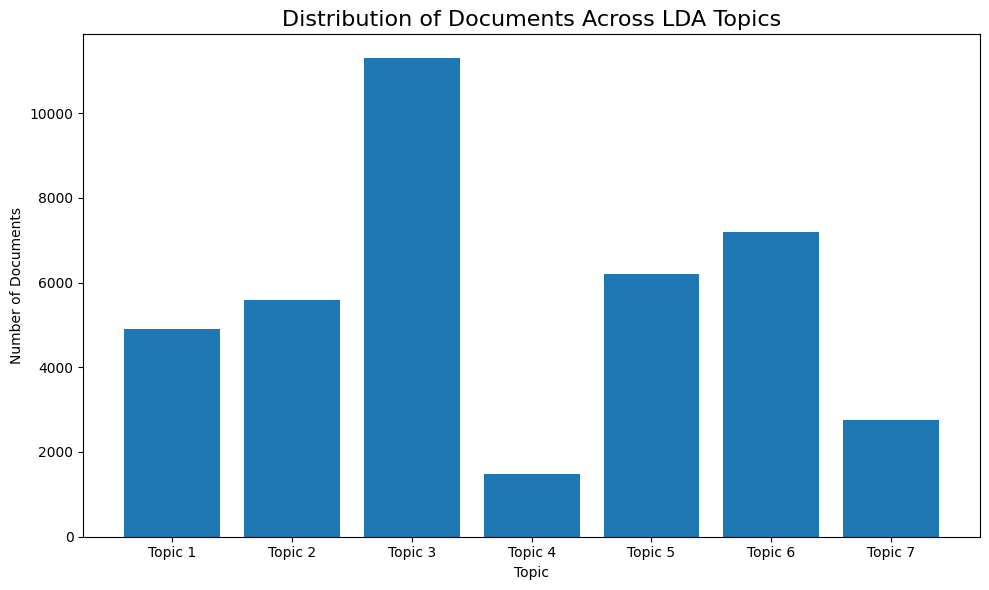


GENERATING pyLDAvis VISUALIZATION

Interactive LDA visualization generated successfully!

LAB COMPLETED SUCCESSFULLY!

Files generated:

1. cleaned_health_headlines.csv
2. top_20_word_frequency.csv
3. lda_topic_results.csv

The notebook performed:

✓ Dataset loading
✓ Missing-value handling
✓ Lowercasing
✓ Tokenization
✓ Stop-word removal
✓ Punctuation removal
✓ Lemmatization
✓ Cleaned text display
✓ Word frequency analysis
✓ Top-20 word visualization
✓ Word cloud
✓ LDA topic modeling
✓ Top 5 words per topic
✓ Topic distribution
✓ Interactive pyLDAvis visualization



In [ ]:
# 1. INSTALL REQUIRED LIBRARIES

!pip -q install nltk wordcloud gensim pyLDAvis


# 2. IMPORT LIBRARIES

import os
import re
import string
import warnings
import requests
import zipfile
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud

from gensim import corpora
from gensim.models import LdaModel

import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

warnings.filterwarnings("ignore")

# Download NLTK resources
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("Libraries loaded successfully!")



# TASK 1: DATA ACQUISITION AND PREPROCESSING


print("\n" + "="*70)
print("TASK 1: DATA ACQUISITION AND PREPROCESSING")
print("="*70)

# GitHub raw URL for the combined dataset
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/"
    "master/Health_Related_Headlines_Dataset.csv"
)

# Load dataset
df = pd.read_csv(DATA_URL)

print("\nDataset loaded successfully!")

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())



# Check missing values

print("\nMissing values:")
print(df.isnull().sum())



# Select text column
df["Headlines"] = df["Headlines"].fillna("")
df["Teaser"] = df["Teaser"].fillna("")

df["text"] = df["Headlines"] + " " + df["Teaser"]

# Remove empty documents
df = df[df["text"].str.strip() != ""].copy()

print("\nNumber of documents after removing empty text:")
print(len(df))


# Text preprocessing


stop_words = set(stopwords.words("english"))

# Additional common words that are not useful for topics
custom_stopwords = {
    "said", "says", "say", "according", "also",
    "new", "one", "two", "may", "could",
    "would", "year", "years", "health"
}

stop_words = stop_words.union(custom_stopwords)

lemmatizer = WordNetLemmatizer()


def clean_text(text):

    # Convert to string
    text = str(text)

    # Lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove numbers
    text = re.sub(r"\d+", " ", text)

    # Remove punctuation
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    # Tokenization
    tokens = nltk.word_tokenize(text)

    # Keep alphabetic words and remove stopwords
    tokens = [
        word for word in tokens
        if word.isalpha() and word not in stop_words
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    # Remove very short words
    tokens = [
        word for word in tokens
        if len(word) > 2
    ]

    return tokens


# Apply preprocessing
df["clean_tokens"] = df["text"].apply(clean_text)

# Convert tokens back into text
df["clean_text"] = df["clean_tokens"].apply(
    lambda x: " ".join(x)
)



# Display cleaned samples


print("\n" + "-"*70)
print("CLEANED TEXT SAMPLES")
print("-"*70)

for i in range(min(5, len(df))):

    print(f"\nSample {i+1}")

    print("Original:")
    print(df.iloc[i]["text"][:500])

    print("\nCleaned:")
    print(df.iloc[i]["clean_text"][:500])

    print("-"*70)



# TASK 2: EXPLORATORY TEXT ANALYSIS

print("\n" + "="*70)
print("TASK 2: EXPLORATORY TEXT ANALYSIS")
print("="*70)



# Create word frequency distribution


all_words = []

for tokens in df["clean_tokens"]:
    all_words.extend(tokens)

word_frequency = Counter(all_words)

print("\nTotal number of tokens:")
print(len(all_words))

print("\nNumber of unique words:")
print(len(word_frequency))



# Top 20 words

top_20 = word_frequency.most_common(20)

freq_df = pd.DataFrame(
    top_20,
    columns=["Word", "Frequency"]
)

print("\nTop 20 most frequent words:")
display(freq_df)



# Plot top 20 words


plt.figure(figsize=(12, 7))

plt.bar(
    freq_df["Word"],
    freq_df["Frequency"]
)

plt.title(
    "Top 20 Most Frequent Words in Health-Related Text",
    fontsize=16
)

plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()



# Word frequency distribution

frequencies = sorted(
    word_frequency.values(),
    reverse=True
)

plt.figure(figsize=(10, 6))

plt.plot(
    frequencies[:100],
    linewidth=2
)

plt.title(
    "Word Frequency Distribution",
    fontsize=16
)

plt.xlabel("Word Rank")
plt.ylabel("Frequency")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



# Word Cloud

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=150,
    collocations=False
).generate_from_frequencies(word_frequency)


plt.figure(figsize=(15, 8))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title(
    "Health-Related Word Cloud",
    fontsize=20
)

plt.show()


# TASK 3: LDA TOPIC MODELING

print("\n" + "="*70)
print("TASK 3: LDA TOPIC MODELING")
print("="*70)


# Prepare documents for LDA

documents = df["clean_tokens"].tolist()

# Remove documents with very few words
documents = [
    doc for doc in documents
    if len(doc) >= 3
]

print("\nDocuments used for LDA:")
print(len(documents))


# Create dictionary

dictionary = corpora.Dictionary(documents)

print("\nInitial vocabulary size:")
print(len(dictionary))



# Remove extremely rare/common words

dictionary.filter_extremes(
    no_below=5,
    no_above=0.5
)

print("\nVocabulary size after filtering:")
print(len(dictionary))


# Create Bag-of-Words corpus

corpus = [
    dictionary.doc2bow(doc)
    for doc in documents
]

print("\nCorpus created successfully!")

print("Number of documents:", len(corpus))
print("Number of vocabulary terms:", len(dictionary))


# TRAIN LDA MODEL

# Number of topics
NUM_TOPICS = 7

print("\nTraining LDA model...")
print("Number of topics:", NUM_TOPICS)

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=NUM_TOPICS,
    random_state=42,
    passes=10,
    iterations=100,
    alpha="auto",
    eta="auto"
)

print("\nLDA model trained successfully!")



# DISPLAY TOP 5 WORDS PER TOPIC

print("\n" + "="*70)
print("TOP 5 WORDS FOR EACH TOPIC")
print("="*70)

for topic_id, topic_words in lda_model.show_topics(
    num_topics=NUM_TOPICS,
    num_words=5,
    formatted=False
):

    words = [
        word
        for word, probability in topic_words
    ]

    print(
        f"\nTopic {topic_id + 1}: "
        + ", ".join(words)
    )


# DISPLAY TOPIC WORD PROBABILITIES

print("\n" + "="*70)
print("TOPIC WORD PROBABILITIES")
print("="*70)

for topic_id in range(NUM_TOPICS):

    print(f"\nTopic {topic_id + 1}")

    words = lda_model.show_topic(
        topic_id,
        topn=5
    )

    for word, probability in words:

        print(
            f"{word:20s} "
            f"{probability:.4f}"
        )


# TOPIC DISTRIBUTION

topic_counts = Counter()

for doc in corpus:

    topic_distribution = lda_model.get_document_topics(
        doc,
        minimum_probability=0
    )

    dominant_topic = max(
        topic_distribution,
        key=lambda x: x[1]
    )[0]

    topic_counts[dominant_topic] += 1


topic_distribution_df = pd.DataFrame(
    {
        "Topic": [
            f"Topic {i+1}"
            for i in range(NUM_TOPICS)
        ],
        "Documents": [
            topic_counts[i]
            for i in range(NUM_TOPICS)
        ]
    }
)

print("\nDominant topic distribution:")
display(topic_distribution_df)


# Plot topic distribution

plt.figure(figsize=(10, 6))

plt.bar(
    topic_distribution_df["Topic"],
    topic_distribution_df["Documents"]
)

plt.title(
    "Distribution of Documents Across LDA Topics",
    fontsize=16
)

plt.xlabel("Topic")
plt.ylabel("Number of Documents")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()



# PYLDAVIS VISUALIZATION

print("\n" + "="*70)
print("GENERATING pyLDAvis VISUALIZATION")
print("="*70)

# Prepare visualization
lda_vis = gensimvis.prepare(
    lda_model,
    corpus,
    dictionary,
    sort_topics=False
)

# Display interactive visualization
pyLDAvis.display(lda_vis)

print("\nInteractive LDA visualization generated successfully!")


# SAVE RESULTS

# Save cleaned dataset
df[
    [
        "Date",
        "Source",
        "Headlines",
        "Category",
        "clean_text"
    ]
].to_csv(
    "cleaned_health_headlines.csv",
    index=False
)

# Save top words
freq_df.to_csv(
    "top_20_word_frequency.csv",
    index=False
)

# Save topic information
topic_results = []

for topic_id in range(NUM_TOPICS):

    words = lda_model.show_topic(
        topic_id,
        topn=10
    )

    topic_results.append(
        {
            "Topic": f"Topic {topic_id + 1}",
            "Top_Words": ", ".join(
                [word for word, prob in words]
            )
        }
    )

topic_results_df = pd.DataFrame(topic_results)

topic_results_df.to_csv(
    "lda_topic_results.csv",
    index=False
)


